# 03 · Top-speed utility: the five kinogram positions

**Run order:** `01_globalization` → `02_acceleration_utility` → `03_top_speed_utility`. Each notebook runs on its own (kernel `anaconda3`) and writes no files.

Tests the top-speed detectors in `stride.py` on one runner, with the run summary from `sprint_summary.py`.

**Where the window starts.** Top speed = the peak of the smoothed speed curve (`sprint_summary`). The window opens
at the **first toe-off at or after top speed** and covers two steps (one off each foot = one full stride).

**Ground contact, the rule every event is built on** (`stride.foot_contacts`). A foot is on the ground when
its lower point (heel or toe landmark) is **within 3 cm of the local floor AND moving slower than 1.5 m/s**.
These are the two thresholds `sprint_report.py` already uses, required together. The local floor is a rolling
10th percentile over ±0.5 s, because the floor drifts 3–5 cm over 60 m and the toe dips 3 cm at every push-off.
On the block pedals the foot sits above the floor, so a foot that is still at frame 0 is on its pedal until it
first moves.

**The five positions** ([ALTIS kinogram method](https://simplifaster.com/articles/altis-kinogram-method/)):

| position | ALTIS definition | how `stride.py` finds it |
|---|---|---|
| toe-off | last frame the support foot is on the ground | last frame of the contact |
| max vertical projection | peak of the flight phase | highest pelvis point between toe-off and touchdown |
| strike | the opposite thigh is vertical | pushing leg's thigh closest to vertical, before touchdown |
| touchdown | first frame the swing foot is on the ground | first frame of the next contact |
| full support | foot directly under the pelvis, toe under the ASIS | first frame the landing toe is behind the ASIS |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sprint_pipeline as SP          # landmark indices, and the current stride finder for comparison
import sprint_summary as SS           # the run in plain numbers (uses stride.py underneath)
import sprint_outputs as OUT          # skeleton drawing
import stride as ST                   # the event detectors under test

RUNNER = "SB80"

## 0 · The run at a glance

In [2]:
run = SS.summarize(RUNNER)
raw, fs = run.trial["raw64"], run.trial["fs"]
peak = int(np.argmax(run.speed))
kino = ST.top_speed_kinogram(raw, run.contacts, peak)    # two KinogramStep objects
pd.Series(run.headline)

runner                      SB80
time_to_60m_s              9.333
top_speed_ms                7.14
time_to_top_speed_s        7.717
distance_at_top_speed_m     48.9
steps_to_top_speed            32
steps_to_60m                  38
avg_stride_length_m         3.22
avg_stride_frequency_hz     2.08
avg_step_frequency_hz       4.15
block_time_s               0.283
missed_contacts                0
dtype: object

## 1 · Where top speed is, and the window analysed

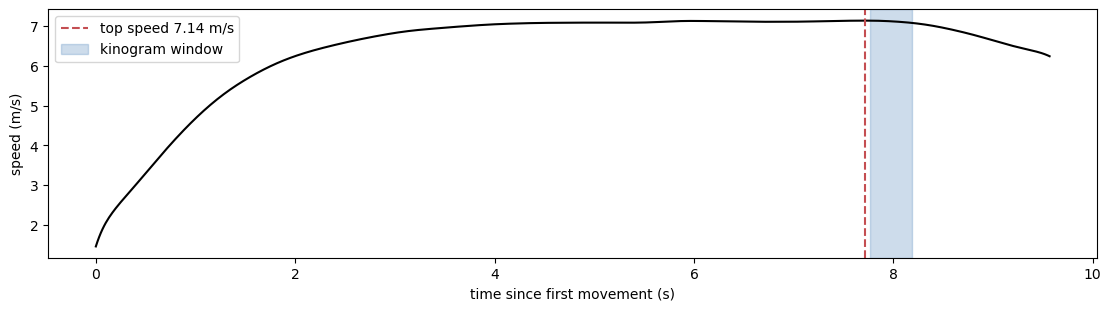

In [3]:
time = np.arange(len(raw)) / fs
fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
ax.plot(time, run.speed, color="k")
ax.axvline(peak / fs, color="#c44e52", ls="--", label=f"top speed {run.speed[peak]:.2f} m/s")
ax.axvspan(kino[0].toe_off / fs, kino[-1].full_support / fs, color="#3a76b3", alpha=0.25, label="kinogram window")
ax.set(xlabel="time since first movement (s)", ylabel="speed (m/s)")
ax.legend();

## 2 · The five positions, both steps (solid = right side, faint = left)

,toe_off,max_vertical,strike,touchdown,full_support,flight_ms,contact_ms
L -> R,466,470,473,474,477,116.666667,116.666667
R -> L,480,484,488,489,491,133.333333,100.000000


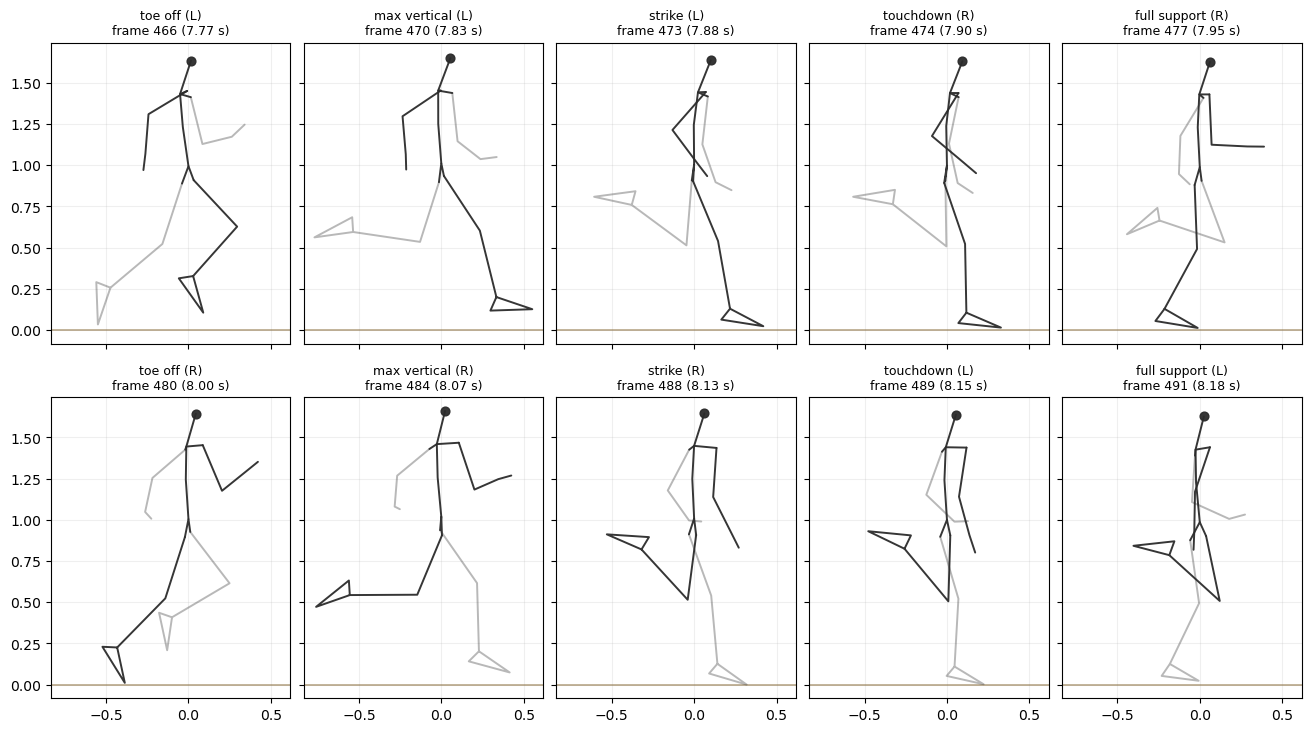

In [4]:
names = ("toe_off", "max_vertical", "strike", "touchdown", "full_support")
OUT.plot_event_strip(raw, [(f"{n.replace('_', ' ')} ({k.off_foot if i < 3 else k.on_foot})", getattr(k, n))
                           for k in kino for i, n in enumerate(names)], fs, ncols=5)

table = pd.DataFrame([{n: getattr(k, n) for n in names} for k in kino],
                     index=[f"{k.off_foot} -> {k.on_foot}" for k in kino])
table["flight_ms"] = (table.touchdown - table.toe_off - 1) / fs * 1000
table["contact_ms"] = [(c.take_off - c.touchdown + 1) / fs * 1000
                       for k in kino for c in run.contacts if c.touchdown == k.touchdown]
table

## 3 · The signal behind each event

Each panel is the quantity one rule reads. Dashed lines = the detected events of the first step.

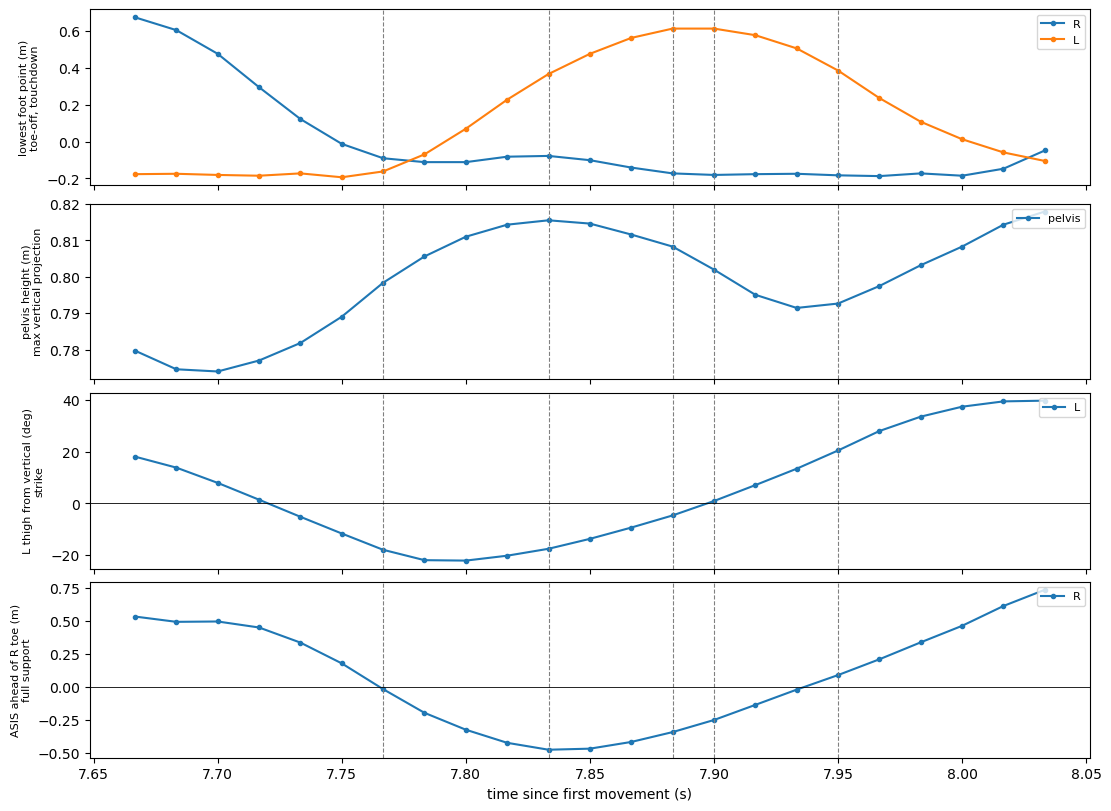

In [5]:
k = kino[0]
w = slice(k.toe_off - 6, (k.full_support or k.touchdown) + 6)
time = np.arange(len(raw)) / fs
signals = {
    "lowest foot point (m)\ntoe-off, touchdown": {f: raw[:, ST.FOOT[f], SP._VERT].min(axis=1) for f in "RL"},
    "pelvis height (m)\nmax vertical projection": {"pelvis": raw[:, SP.MK_PELVIS_ALL, SP._VERT].mean(axis=1)},
    f"{k.off_foot} thigh from vertical (deg)\nstrike": {k.off_foot: ST.thigh_from_vertical(raw, k.off_foot)},
    f"ASIS ahead of {k.on_foot} toe (m)\nfull support": {
        k.on_foot: raw[:, ST.ASIS, SP._AP].mean(axis=1) - raw[:, ST.FOOT[k.on_foot][1], SP._AP]},
}
fig, axes = plt.subplots(len(signals), 1, figsize=(11, 8), sharex=True, constrained_layout=True)
for ax, (label, lines) in zip(axes, signals.items()):
    for name, y in lines.items():
        ax.plot(time[w], y[w], marker=".", label=name)
    ax.set_ylabel(label, fontsize=8)
    ax.legend(fontsize=8, loc="upper right")
    for n in names:
        if getattr(k, n) is not None:
            ax.axvline(getattr(k, n) / fs, color="grey", ls="--", lw=0.8)
axes[2].axhline(0, color="k", lw=0.6)
axes[3].axhline(0, color="k", lw=0.6)
axes[-1].set_xlabel("time since first movement (s)");

## 4 · Compared with the current pipeline

`SP.find_top_speed_strides` (used by every current model) differs in two ways:

1. Its "contact" is the **lowest frame of the foot-segment centre**: a single frame that can land anywhere from
   touchdown into mid-stance (last column: frames after the true touchdown). It has no take-off at all.
2. It centres the strides on the **raw** speed peak (`clean_for_angles`' `peak_frame`), not the smoothed one.

In [6]:
old_windows, _ = SP.find_top_speed_strides(run.trial["mk"], run.trial["peak_frame"])
right_td = [c.touchdown for c in run.contacts if c.foot == "R" and not c.on_blocks]
print(f"raw speed peak (current pipeline): frame {run.trial['peak_frame']} = {run.trial['peak_frame'] / fs:.2f} s, "
      f"{run.distance[run.trial['peak_frame']]:.1f} m")
print(f"smoothed speed peak (this notebook): frame {peak} = {peak / fs:.2f} s, {run.distance[peak]:.1f} m")
pd.DataFrame({"current_contact_frame": [a for a, _ in old_windows],
              "nearest_new_touchdown": [min(right_td, key=lambda f: abs(f - a)) for a, _ in old_windows]}
             ).assign(frames_late=lambda d: d.current_contact_frame - d.nearest_new_touchdown)

raw speed peak (current pipeline): frame 354 = 5.90 s, 36.0 m
smoothed speed peak (this notebook): frame 463 = 7.72 s, 48.9 m


,current_contact_frame,nearest_new_touchdown,frames_late
0,274,274,0
1,302,301,1
2,330,327,3
3,358,358,0
4,387,388,-1


## 5 · Self-checks

In [7]:
for k in kino:
    assert k.toe_off < k.max_vertical <= k.strike < k.touchdown, f"{k.off_foot}->{k.on_foot}: flight events out of order"
    assert k.full_support is not None and k.touchdown <= k.full_support, "full support must be in stance"
    assert k.off_foot != k.on_foot
assert kino[0].toe_off >= peak, "the window must start at or after top speed"
assert table.contact_ms.between(50, 200).all() and table.flight_ms.between(50, 200).all()
print("top-speed checks passed")

top-speed checks passed
